<a href="https://colab.research.google.com/github/archanashinde001/multimodal-stance-models/blob/main/multimodal_model_comparison_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Comparing open-weight models for stance in multimodal social-media posts

**What this notebook measures.** Every pretrained model is used as a *frozen feature extractor* (post -> vector of
numbers). The same small classifier is trained on every set of vectors, so the scores show
how much stance information can be recovered from each model's representation. Absolute scores are lower
bounds; the differences between input conditions are the result.

**Below are some comparisons of the modality done in this notebook:**

| | Comparison | Systems | Scored on |
|---|---|---|---|
| C1 | Text models | RoBERTa-base, GPT-Neo-125M, TinyLlama-1.1B, CLIP Text | message label |
| C2 | Vision models | ResNet18, ViT-B/16, CLIP Image | image label |
| C3 | CLIP: text only, image only, text + image | CLIP Text, CLIP Image, CLIP Text + Image | both labels |
| C4 | SmolVLM: input type and model size | 256M and 500M, each with text only, image only, text + image | both labels |

Each system is scored on the label of the input it sees. Systems that see text and image are scored on both labels.
The majority-class row (always predicts the most common class) is a reference point, not a model.

**Supplemental runs:** RoBERTa + ResNet18 (two models joined), SmolVLM vs CLIP with text + image, and per-class F1.

**Run:** upload `text.xlsx`, `images.xlsx` and `images.zip` to `/content/study`, choose a T4 GPU, then *Runtime > Run all*.


In [18]:
# transformers: loads the pretrained models; accelerate: faster model loading; openpyxl: reads Excel files
!pip -q install transformers accelerate openpyxl

In [19]:
# ================= Settings =================
from pathlib import Path

BASE       = Path("/content/study")       # folder with the three input files
TEXT_XLSX  = BASE / "text.xlsx"
IMAGE_XLSX = BASE / "images.xlsx"
IMAGES_ZIP = BASE / "images.zip"
IMAGE_DIR  = BASE / "images"              # the zip is extracted here
OUT        = BASE / "results"             # tables and figures are written here (overwritten each run)

# Column names in the Excel files
ID_COL, TEXT_COL = "ID", "Message"
MESSAGE_LABEL_COL = "Label_message"
IMAGE_LABEL_COL   = "Image_label"

def image_stem(post_id):
    """Image file name (without extension) for a post ID. Edit if your files are named differently."""
    return str(post_id)

CLASSES = ["Anti-Mandate", "Pro-Mandate", "Neutral", "Other"]

SEED      = 42     # one seed for everything, so every run gives the same splits and results
N_FOLDS   = 5      # cross-validation folds (reduced automatically if the rarest class is smaller)
N_REPEATS = 5      # cross-validation is repeated with 5 different shuffles
N_BOOT    = 1000   # bootstrap resamples for the 95% intervals
C_VALUE   = 1.0    # logistic regression strength, fixed for every model (tuning it inside each fold gave no improvement)
MAX_TEXT_TOKENS = 128   # RoBERTa / GPT-Neo / TinyLlama read at most this many tokens per post

MODEL_IDS = {
    "RoBERTa-base":   "roberta-base",
    "GPT-Neo-125M":   "EleutherAI/gpt-neo-125M",
    "TinyLlama-1.1B": "TinyLlama/TinyLlama-1.1B-Chat-v1.0",
    "CLIP":           "openai/clip-vit-base-patch16",
    "SmolVLM-256M":   "HuggingFaceTB/SmolVLM-256M-Instruct",
    "SmolVLM-500M":   "HuggingFaceTB/SmolVLM-500M-Instruct",
}   # ResNet18 and ViT-B/16 come from torchvision (ImageNet weights)

In [20]:
# ================= Setup =================
import json, gc, time, zipfile, warnings
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)
np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, "(a T4 GPU is recommended: Runtime > Change runtime type)")

OUT.mkdir(parents=True, exist_ok=True)
(OUT / "supplement").mkdir(exist_ok=True)

# Software versions, saved next to the results so the run can be reproduced
from importlib.metadata import version, PackageNotFoundError
def _ver(pkg):
    try: return f"{pkg}=={version(pkg)}"
    except PackageNotFoundError: return f"{pkg} (not installed)"
versions = [_ver(p) for p in ["torch", "torchvision", "transformers", "scikit-learn", "pandas", "numpy", "Pillow"]]
(OUT / "versions.txt").write_text("\n".join(versions) + f"\ndevice={DEVICE}\nseed={SEED}\n")
print("\n".join(versions))

device: cuda (a T4 GPU is recommended: Runtime > Change runtime type)
torch==2.11.0+cu130
torchvision==0.26.0+cu130
transformers==5.20.2
scikit-learn==1.6.1
pandas==2.2.3
numpy==2.1.3
Pillow==11.3.0


In [21]:
# ================= 1. Load the data =================
if not IMAGE_DIR.exists():
    with zipfile.ZipFile(IMAGES_ZIP) as z:
        z.extractall(IMAGE_DIR)

txt = pd.read_excel(TEXT_XLSX)
img = pd.read_excel(IMAGE_XLSX)
# validate="one_to_one" stops with an error if an ID appears twice
df = txt[[ID_COL, TEXT_COL, MESSAGE_LABEL_COL]].merge(
    img[[ID_COL, IMAGE_LABEL_COL]], on=ID_COL, how="inner", validate="one_to_one")
print(len(txt), "text rows |", len(img), "image rows |", len(df), "posts after matching by ID")

# No text cleaning: hashtags, emojis and capitals can carry stance.
df["text"] = df[TEXT_COL].astype(str).str.strip()
for c in (MESSAGE_LABEL_COL, IMAGE_LABEL_COL):
    df[c] = df[c].astype(str).str.strip()
unknown = (set(df[MESSAGE_LABEL_COL]) | set(df[IMAGE_LABEL_COL])) - set(CLASSES)
assert not unknown, f"Labels not in CLASSES (typo or extra spaces?): {unknown}"

files = {p.stem: p for p in IMAGE_DIR.rglob("*")
         if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp", ".gif"}}
df["path"] = [files.get(image_stem(i)) for i in df[ID_COL]]
n_missing = int(df["path"].isna().sum())
assert n_missing == 0, f"{n_missing} posts have no image file. Edit image_stem(). Example file names: {list(files)[:3]}"

LABEL_COLS = {"message": MESSAGE_LABEL_COL, "image": IMAGE_LABEL_COL}
Y = {lab: df[col].to_numpy(dtype=object) for lab, col in LABEL_COLS.items()}
texts, paths = df["text"].tolist(), df["path"].tolist()

200 text rows | 200 image rows | 200 posts after matching by ID


In [22]:
# ================= 2. Look at the data =================
for lab, col in LABEL_COLS.items():
    print(f"\n{lab.upper()} LABEL counts:")
    print(df[col].value_counts().reindex(CLASSES).fillna(0).astype(int).to_string())

print("\nMessage label (rows) vs image label (columns):")
print(pd.crosstab(df[MESSAGE_LABEL_COL], df[IMAGE_LABEL_COL]).reindex(index=CLASSES, columns=CLASSES, fill_value=0))

# Posts with identical text (but different images) share a group id, so that cross-validation
# never puts one copy in training and the other in testing.
groups = pd.factorize(df["text"].str.lower().str.strip())[0]
print(f"\n{len(df)} posts, {len(set(groups))} distinct texts")


MESSAGE LABEL counts:
Label_message
Anti-Mandate    30
Pro-Mandate     45
Neutral         34
Other           91

IMAGE LABEL counts:
Image_label
Anti-Mandate     40
Pro-Mandate     126
Neutral          26
Other             8

Message label (rows) vs image label (columns):
Image_label    Anti-Mandate  Pro-Mandate  Neutral  Other
Label_message                                           
Anti-Mandate             17            3        5      5
Pro-Mandate               3           39        2      1
Neutral                   6           21        7      0
Other                    14           63       12      2

200 posts, 195 distinct texts


In [23]:
# ================= 3. Cross-validation splits =================
# Made once per label at the start of the run and used by EVERY model.
# Stratified = similar class proportions in every fold; grouped = duplicate texts stay together.
# The fixed seed gives identical splits on every run. They are saved to a file as a record only.
def make_splits(y, groups):
    smallest = int(pd.Series(y).value_counts().min())
    n_splits = max(2, min(N_FOLDS, smallest))
    if n_splits < N_FOLDS:
        print(f"  note: rarest class has {smallest} posts, using {n_splits} folds")
    splits = []
    for r in range(N_REPEATS):
        cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=SEED + r)
        for tr, te in cv.split(np.zeros(len(y)), y, groups):
            assert not set(groups[tr]) & set(groups[te]), "duplicate text in both train and test"
            splits.append((r, tr, te))
    return splits

SPLITS = {lab: make_splits(Y[lab], groups) for lab in LABEL_COLS}
for lab, s in SPLITS.items():
    json.dump([[r, tr.tolist(), te.tolist()] for r, tr, te in s], open(OUT / f"splits_{lab}_label.json", "w"))
print("splits ready:", {lab: len(s) for lab, s in SPLITS.items()}, "train/test splits per label")

# Posts per class in training and testing (over the 25 splits of each label)
rows = []
for lab, s in SPLITS.items():
    y = Y[lab]
    for c in CLASSES + ["All classes"]:
        is_c = np.ones(len(y), bool) if c == "All classes" else (y == c)
        n_tr = [int(is_c[tr].sum()) for _, tr, _ in s]
        n_te = [int(is_c[te].sum()) for _, _, te in s]
        rows.append({"Label": lab, "Class": c, "Total": int(is_c.sum()),
                     "Train per fold (mean)": round(np.mean(n_tr), 1), "Train (min-max)": f"{min(n_tr)}-{max(n_tr)}",
                     "Test per fold (mean)": round(np.mean(n_te), 1), "Test (min-max)": f"{min(n_te)}-{max(n_te)}"})
SPLIT_TABLE = pd.DataFrame(rows)
SPLIT_TABLE.to_csv(OUT / "table_data_train_test_per_class.csv", index=False)
print("\n=== Posts per class in training and testing ===")
print(SPLIT_TABLE.to_string(index=False))

splits ready: {'message': 25, 'image': 25} train/test splits per label

=== Posts per class in training and testing ===
  Label        Class  Total  Train per fold (mean) Train (min-max)  Test per fold (mean) Test (min-max)
message Anti-Mandate     30                   24.0           21-29                   6.0            1-9
message  Pro-Mandate     45                   36.0           32-41                   9.0           4-13
message      Neutral     34                   27.2           24-31                   6.8           3-10
message        Other     91                   72.8           68-78                  18.2          13-23
message  All classes    200                  160.0         156-163                  40.0          37-44
  image Anti-Mandate     40                   32.0           28-37                   8.0           3-12
  image  Pro-Mandate    126                  100.8          95-107                  25.2          19-31
  image      Neutral     26                   20

## 4. Feature extraction
Each function turns the posts into a matrix with one row per post. The models are frozen; we only read their internal vectors.
- Text models: average the model's token vectors over the post (mean pooling).
- Image models: take the vector the model produces just before its classification layer.
- SmolVLM: the model reads image and/or text and we average its final hidden states.
- CLIP: its text vector and its image vector (both in the same 512-d space). *Text + image* = the two vectors side by side.
  

In [24]:
def free_gpu():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

def load_rgb(path):
    return Image.open(path).convert("RGB")

def embed_text(model_id, texts, batch_size=16):
    """RoBERTa / GPT-Neo / TinyLlama: mean of the last hidden layer over the post's tokens."""
    from transformers import AutoTokenizer, AutoModel
    dtype = torch.float16 if DEVICE == "cuda" else torch.float32
    tok = AutoTokenizer.from_pretrained(model_id)
    if tok.pad_token is None:                       # GPT-style models have no padding token
        tok.pad_token = tok.eos_token
    n_cut = sum(len(ids) > MAX_TEXT_TOKENS for ids in tok(texts)["input_ids"])
    print(f"    {n_cut} posts longer than {MAX_TEXT_TOKENS} tokens (cut)")
    model = AutoModel.from_pretrained(model_id, torch_dtype=dtype).to(DEVICE).eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(texts), batch_size):
            enc = tok(texts[i:i + batch_size], padding=True, truncation=True,
                      max_length=MAX_TEXT_TOKENS, return_tensors="pt").to(DEVICE)
            h = model(**enc).last_hidden_state                       # (batch, tokens, dim)
            m = enc["attention_mask"].unsqueeze(-1).to(h.dtype)      # ignore padding
            out.append(((h * m).sum(1) / m.sum(1)).float().cpu().numpy())
    del model; free_gpu()
    return np.vstack(out)

def embed_image(arch, paths, batch_size=32):
    """ResNet18 / ViT-B/16 (torchvision, ImageNet weights), classification layer removed."""
    from torchvision import models
    if arch == "resnet18":
        weights = models.ResNet18_Weights.DEFAULT
        model = models.resnet18(weights=weights); model.fc = torch.nn.Identity()
    else:
        weights = models.ViT_B_16_Weights.DEFAULT
        model = models.vit_b_16(weights=weights); model.heads = torch.nn.Identity()
    prep = weights.transforms()                    # the resize/normalise recipe the model was trained with
    model = model.to(DEVICE).eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(paths), batch_size):
            batch = torch.stack([prep(load_rgb(p)) for p in paths[i:i + batch_size]]).to(DEVICE)
            out.append(model(batch).float().cpu().numpy())
    del model; free_gpu()
    return np.vstack(out)

def embed_clip(model_id, texts, paths, batch_size=32):
    """CLIP: text vectors and image vectors in the same space, each scaled to length 1."""
    from transformers import CLIPModel, CLIPProcessor
    proc = CLIPProcessor.from_pretrained(model_id)
    model = CLIPModel.from_pretrained(model_id).to(DEVICE).eval()
    as_tensor = lambda o: o if torch.is_tensor(o) else o.pooler_output   # works across transformers versions
    max_len = proc.tokenizer.model_max_length                             # 77 for CLIP
    n_cut = sum(len(ids) > max_len for ids in proc.tokenizer(texts)["input_ids"])
    print(f"    {n_cut} posts longer than CLIP's {max_len}-token limit (cut)")
    T, I = [], []
    with torch.no_grad():
        for i in range(0, len(texts), batch_size):
            enc = proc.tokenizer(texts[i:i + batch_size], padding=True, truncation=True,
                                 max_length=max_len, return_tensors="pt").to(DEVICE)
            T.append(as_tensor(model.get_text_features(**enc)).float().cpu())
            pix = proc(images=[load_rgb(p) for p in paths[i:i + batch_size]], return_tensors="pt")["pixel_values"].to(DEVICE)
            I.append(as_tensor(model.get_image_features(pixel_values=pix)).float().cpu())
    del model; free_gpu()
    unit = lambda x: torch.nn.functional.normalize(torch.cat(x), dim=-1).numpy()
    return unit(T), unit(I)

def embed_smolvlm(model_id, texts, paths, mode):
    """SmolVLM reads the question first, then the meme and/or the post; we average its last hidden states
    over all input tokens.
    mode = 'text'  : question + post
           'image' : question + meme
           'both'  : question + meme + post"""
    from transformers import AutoProcessor, AutoModelForImageTextToText
    proc = AutoProcessor.from_pretrained(model_id, do_image_splitting=False)   # one 512-px view per meme
    model = AutoModelForImageTextToText.from_pretrained(model_id, torch_dtype=torch.float32).to(DEVICE).eval()
    use_image, use_text = mode in ("image", "both"), mode in ("text", "both")
    out = []
    with torch.no_grad():
        for t, p in zip(texts, paths):
            # The question comes FIRST, so the content that follows is read with the task in mind.
            # It names the task but never the labels or the answer.
            question = ("What is the stance of this post on vaccine mandates?\n" if use_text
                        else "What is the stance of this image on vaccine mandates?\n")
            content = ([{"type": "text", "text": question}]
                       + ([{"type": "image"}] if use_image else [])
                       + ([{"type": "text", "text": f'Social media post: "{t}"'}] if use_text else []))
            prompt = proc.apply_chat_template([{"role": "user", "content": content}], add_generation_prompt=True)
            inputs = (proc(text=prompt, images=[load_rgb(p)], return_tensors="pt") if use_image
                      else proc(text=prompt, return_tensors="pt")).to(DEVICE)
            hs = model(**inputs, output_hidden_states=True).hidden_states[-1]
            m = inputs["attention_mask"].unsqueeze(-1).to(hs.dtype)
            out.append(((hs * m).sum(1) / m.sum(1)).float().cpu().numpy())
    del model; free_gpu()
    return np.vstack(out)

In [25]:
# ================= Run every extractor (fresh each run) =================
FEATS = {}
def run(name, fn):
    t0 = time.time(); print("extracting", name)
    FEATS[name] = fn()
    print(f"    {FEATS[name].shape[0]} posts x {FEATS[name].shape[1]} features  ({time.time() - t0:.0f}s)")

run("RoBERTa-base",   lambda: embed_text(MODEL_IDS["RoBERTa-base"], texts))
run("GPT-Neo-125M",   lambda: embed_text(MODEL_IDS["GPT-Neo-125M"], texts))
run("TinyLlama-1.1B", lambda: embed_text(MODEL_IDS["TinyLlama-1.1B"], texts))
run("ResNet18",       lambda: embed_image("resnet18", paths))
run("ViT-B/16",       lambda: embed_image("vit_b_16", paths))

t0 = time.time(); print("extracting CLIP Text and CLIP Image")
FEATS["CLIP Text"], FEATS["CLIP Image"] = embed_clip(MODEL_IDS["CLIP"], texts, paths)
print(f"    {FEATS['CLIP Text'].shape} and {FEATS['CLIP Image'].shape}  ({time.time() - t0:.0f}s)")

for size in ("256M", "500M"):
    for mode in ("text", "image", "both"):
        run(f"SmolVLM-{size} {mode}", lambda s=size, m=mode: embed_smolvlm(MODEL_IDS[f"SmolVLM-{s}"], texts, paths, m))

extracting RoBERTa-base


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (858 > 512). Running this sequence through the model will result in indexing errors


    13 posts longer than 128 tokens (cut)


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


...

    200 posts x 960 features  (14s)
extracting SmolVLM-500M image


Loading weights:   0%|          | 0/489 [00:00<?, ?it/s]

    200 posts x 960 features  (55s)
extracting SmolVLM-500M both


Loading weights:   0%|          | 0/489 [00:00<?, ?it/s]

    200 posts x 960 features  (56s)


## 5. Linear probe
One row per system: its category, the features it uses, and the labels it is scored on.
Every system gets one out-of-fold prediction per post in each of the 5 repeats.

In [26]:
# name: (category, feature parts, labels it is scored on). None = no features (majority class).
SYSTEMS = {
    "Majority class":          ("reference",       None,                          ["message", "image"]),
    # C1 text models
    "RoBERTa-base":            ("text model",      ["RoBERTa-base"],              ["message"]),
    "GPT-Neo-125M":            ("text model",      ["GPT-Neo-125M"],              ["message"]),
    "TinyLlama-1.1B":          ("text model",      ["TinyLlama-1.1B"],            ["message"]),
    "CLIP Text":               ("CLIP",            ["CLIP Text"],                 ["message"]),
    # C2 vision models
    "ResNet18":                ("vision model",    ["ResNet18"],                  ["image"]),
    "ViT-B/16":                ("vision model",    ["ViT-B/16"],                  ["image"]),
    "CLIP Image":              ("CLIP",            ["CLIP Image"],                ["image"]),
    # C3 CLIP with both inputs: text vector and image vector side by side
    "CLIP Text + Image":       ("CLIP",            ["CLIP Text", "CLIP Image"],   ["message", "image"]),
    # Supplement: two separate models joined (RoBERTa vector and ResNet18 vector side by side)
    "RoBERTa + ResNet18":      ("supplement",      ["RoBERTa-base", "ResNet18"],  ["message", "image"]),
}
# C4 SmolVLM: two sizes x three inputs
for size in ("256M", "500M"):
    SYSTEMS[f"SmolVLM-{size} text only"]    = ("SmolVLM", [f"SmolVLM-{size} text"],  ["message"])
    SYSTEMS[f"SmolVLM-{size} image only"]   = ("SmolVLM", [f"SmolVLM-{size} image"], ["image"])
    SYSTEMS[f"SmolVLM-{size} text + image"] = ("SmolVLM", [f"SmolVLM-{size} both"],  ["message", "image"])

def make_classifier(parts):
    if parts is None:                    # always predicts the most common class of the training fold
        return DummyClassifier(strategy="most_frequent")
    # StandardScaler is fitted on the training posts only; balanced weights stop rare classes being ignored
    return make_pipeline(StandardScaler(), LogisticRegression(C=C_VALUE, class_weight="balanced", max_iter=1000))

PRED = {}   # (label, system) -> predictions, shape (repeats, posts)
for name, (cat, parts, labels) in SYSTEMS.items():
    X = np.zeros((len(df), 1)) if parts is None else np.hstack([FEATS[p] for p in parts])
    for lab in labels:
        y = Y[lab]
        oof = np.empty((N_REPEATS, len(y)), dtype=object)
        for r, tr, te in SPLITS[lab]:
            oof[r, te] = make_classifier(parts).fit(X[tr], y[tr]).predict(X[te])
        PRED[(lab, name)] = oof
print(len(PRED), "system-label combinations done")

21 system-label combinations done


## 6. Scores and 95% intervals
**Macro-F1** averages the F1 of the four classes equally, so rare classes count as much as common ones.
The score of a system is its macro-F1 averaged over the 5 repeats.
With 200 posts, another sample of 200 would give somewhat different scores. We resample the posts
1,000 times (bootstrap) and report the range that holds the middle 95% of the resampled scores.


In [27]:
def macro_f1(y, p, k):
    """Macro-F1 over classes present in y or p (same as sklearn), written for speed."""
    tp = np.bincount(y[y == p], minlength=k)
    denom = np.bincount(y, minlength=k) + np.bincount(p, minlength=k)
    present = denom > 0
    return np.mean(2 * tp[present] / denom[present])

K = len(CLASSES); CODE = {c: i for i, c in enumerate(CLASSES)}
encode = lambda a: np.vectorize(CODE.get)(a)
Y_CODE = {lab: encode(y) for lab, y in Y.items()}
rng = np.random.default_rng(SEED)
BOOT = {lab: rng.integers(0, len(df), (N_BOOT, len(df))) for lab in LABEL_COLS}   # same resamples for every system

def balanced_accuracy(y, p, k):
    """Average recall over the classes present in y (same as sklearn). Supplement only."""
    n_true = np.bincount(y, minlength=k); tp = np.bincount(y[y == p], minlength=k)
    present = n_true > 0
    return np.mean(tp[present] / n_true[present])

def boot_scores(lab, name, metric=macro_f1):
    """Score (mean over repeats) on the full data and on each bootstrap resample."""
    y, P = Y_CODE[lab], encode(PRED[(lab, name)])
    full = np.mean([metric(y, p, K) for p in P])
    boots = np.array([np.mean([metric(y[idx], p[idx], K) for p in P]) for idx in BOOT[lab]])
    return full, boots

SCORES = {key: boot_scores(*key) for key in PRED}
ci = lambda b: (np.percentile(b, 2.5), np.percentile(b, 97.5))
fmt_ci = lambda lo, hi: f"[{lo:.2f}, {hi:.2f}]"

def score_table(lab, names):
    rows = []
    for n in names:
        full, boots = SCORES[(lab, n)]; lo, hi = ci(boots)
        rows.append({"System": n, "Macro-F1": full, "CI low": lo, "CI high": hi})
    return pd.DataFrame(rows)

def diff_table(pairs):
    """pairs: (label, system A, system B). Difference = macro-F1 of A minus macro-F1 of B."""
    rows = []
    for lab, a, b in pairs:
        (fa, ba), (fb, bb) = SCORES[(lab, a)], SCORES[(lab, b)]
        lo, hi = ci(ba - bb)
        rows.append({"Label": lab, "System A": a, "System B": b, "Macro-F1 A": fa, "Macro-F1 B": fb,
                     "Difference (A - B)": fa - fb, "CI low": lo, "CI high": hi})
    return pd.DataFrame(rows)

def show(T, title, file):
    """Save the numbers to CSV; print each estimate with its 95% interval in one column."""
    T.round(4).to_csv(OUT / file, index=False)
    D = T.copy()
    est = "Difference (A - B)" if "Difference (A - B)" in D else "Macro-F1"
    D[f"{est} [95% interval]"] = [f"{e:.2f} {fmt_ci(l, h)}" for e, l, h in zip(D.pop(est), D.pop("CI low"), D.pop("CI high"))]
    print(f"\n=== {title} ===")
    print(D.round(2).to_string(index=False))

## C1. Text models (message label)

In [28]:
C1_SYSTEMS = ["RoBERTa-base", "GPT-Neo-125M", "TinyLlama-1.1B", "CLIP Text"]
show(score_table("message", ["Majority class"] + C1_SYSTEMS),
     "Table C1a. Text models, message label", "table_C1a_text_models.csv")
show(diff_table([("message", a, b) for i, a in enumerate(C1_SYSTEMS) for b in C1_SYSTEMS[i + 1:]]),
     "Table C1b. Differences between text models", "table_C1b_text_model_differences.csv")


=== Table C1a. Text models, message label ===
        System Macro-F1 [95% interval]
Majority class       0.16 [0.14, 0.17]
  RoBERTa-base       0.56 [0.50, 0.61]
  GPT-Neo-125M       0.56 [0.51, 0.62]
TinyLlama-1.1B       0.60 [0.54, 0.65]
     CLIP Text       0.62 [0.56, 0.67]

=== Table C1b. Differences between text models ===
  Label       System A       System B  Macro-F1 A  Macro-F1 B Difference (A - B) [95% interval]
message   RoBERTa-base   GPT-Neo-125M        0.56        0.56               -0.00 [-0.06, 0.05]
message   RoBERTa-base TinyLlama-1.1B        0.56        0.60               -0.03 [-0.08, 0.01]
message   RoBERTa-base      CLIP Text        0.56        0.62               -0.05 [-0.11, 0.00]
message   GPT-Neo-125M TinyLlama-1.1B        0.56        0.60               -0.03 [-0.08, 0.01]
message   GPT-Neo-125M      CLIP Text        0.56        0.62               -0.05 [-0.11, 0.01]
message TinyLlama-1.1B      CLIP Text        0.60        0.62               -0.02 [-0.08, 0

## C2. Vision models (image label)

In [29]:
C2_SYSTEMS = ["ResNet18", "ViT-B/16", "CLIP Image"]
show(score_table("image", ["Majority class"] + C2_SYSTEMS),
     "Table C2a. Vision models, image label", "table_C2a_vision_models.csv")
show(diff_table([("image", a, b) for i, a in enumerate(C2_SYSTEMS) for b in C2_SYSTEMS[i + 1:]]),
     "Table C2b. Differences between vision models", "table_C2b_vision_model_differences.csv")


=== Table C2a. Vision models, image label ===
        System Macro-F1 [95% interval]
Majority class       0.19 [0.18, 0.21]
      ResNet18       0.43 [0.36, 0.50]
      ViT-B/16       0.38 [0.31, 0.45]
    CLIP Image       0.55 [0.44, 0.63]

=== Table C2b. Differences between vision models ===
Label System A   System B  Macro-F1 A  Macro-F1 B Difference (A - B) [95% interval]
image ResNet18   ViT-B/16        0.43        0.38                0.05 [-0.01, 0.10]
image ResNet18 CLIP Image        0.43        0.55              -0.12 [-0.20, -0.03]
image ViT-B/16 CLIP Image        0.38        0.55              -0.17 [-0.25, -0.07]


## C3. CLIP: text only, image only, text + image
Text only is scored on the message label, image only on the image label, and text + image on both.

In [30]:
C3 = pd.concat([score_table("message", ["Majority class", "CLIP Text", "CLIP Text + Image"]).assign(Label="message"),
                score_table("image",   ["Majority class", "CLIP Image", "CLIP Text + Image"]).assign(Label="image")])
show(C3[["Label", "System", "Macro-F1", "CI low", "CI high"]], "Table C3a. CLIP by input", "table_C3a_clip.csv")
show(diff_table([("message", "CLIP Text + Image", "CLIP Text"),
                 ("image",   "CLIP Text + Image", "CLIP Image")]),
     "Table C3b. CLIP: text + image compared with one input", "table_C3b_clip_differences.csv")


=== Table C3a. CLIP by input ===
  Label            System Macro-F1 [95% interval]
message    Majority class       0.16 [0.14, 0.17]
message         CLIP Text       0.62 [0.56, 0.67]
message CLIP Text + Image       0.61 [0.56, 0.66]
  image    Majority class       0.19 [0.18, 0.21]
  image        CLIP Image       0.55 [0.44, 0.63]
  image CLIP Text + Image       0.60 [0.50, 0.67]

=== Table C3b. CLIP: text + image compared with one input ===
  Label          System A   System B  Macro-F1 A  Macro-F1 B Difference (A - B) [95% interval]
message CLIP Text + Image  CLIP Text        0.61        0.62               -0.00 [-0.05, 0.04]
  image CLIP Text + Image CLIP Image        0.60        0.55                0.04 [-0.00, 0.10]


## C4. SmolVLM: input type and model size
Six systems: two sizes x three inputs. **Input-type differences** hold the size fixed and compare text + image with one input.
**Size differences** hold the input fixed and compare 500M with 256M.

In [31]:
SIZES = ("256M", "500M")
C4 = pd.concat([score_table("message", ["Majority class"] + [f"SmolVLM-{s} {i}" for s in SIZES for i in ("text only", "text + image")]).assign(Label="message"),
                score_table("image",   ["Majority class"] + [f"SmolVLM-{s} {i}" for s in SIZES for i in ("image only", "text + image")]).assign(Label="image")])
show(C4[["Label", "System", "Macro-F1", "CI low", "CI high"]], "Table C4a. SmolVLM by size and input", "table_C4a_smolvlm.csv")

C4_INPUT = [("message", f"SmolVLM-{s} text + image", f"SmolVLM-{s} text only") for s in SIZES] \
         + [("image",   f"SmolVLM-{s} text + image", f"SmolVLM-{s} image only") for s in SIZES]
C4_SIZE  = [("message", "SmolVLM-500M text only",    "SmolVLM-256M text only"),
            ("image",   "SmolVLM-500M image only",   "SmolVLM-256M image only"),
            ("message", "SmolVLM-500M text + image", "SmolVLM-256M text + image"),
            ("image",   "SmolVLM-500M text + image", "SmolVLM-256M text + image")]
show(diff_table(C4_INPUT), "Table C4b. SmolVLM input-type differences (size fixed)", "table_C4b_smolvlm_input.csv")
show(diff_table(C4_SIZE),  "Table C4c. SmolVLM size differences (input fixed)",      "table_C4c_smolvlm_size.csv")


=== Table C4a. SmolVLM by size and input ===
  Label                    System Macro-F1 [95% interval]
message            Majority class       0.16 [0.14, 0.17]
message    SmolVLM-256M text only       0.56 [0.50, 0.61]
message SmolVLM-256M text + image       0.53 [0.46, 0.58]
message    SmolVLM-500M text only       0.57 [0.51, 0.63]
message SmolVLM-500M text + image       0.53 [0.47, 0.59]
  image            Majority class       0.19 [0.18, 0.21]
  image   SmolVLM-256M image only       0.51 [0.40, 0.59]
  image SmolVLM-256M text + image       0.52 [0.43, 0.60]
  image   SmolVLM-500M image only       0.52 [0.43, 0.59]
  image SmolVLM-500M text + image       0.51 [0.41, 0.59]

=== Table C4b. SmolVLM input-type differences (size fixed) ===
  Label                  System A                System B  Macro-F1 A  Macro-F1 B Difference (A - B) [95% interval]
message SmolVLM-256M text + image  SmolVLM-256M text only        0.53        0.56               -0.03 [-0.09, 0.03]
message SmolVLM-500M

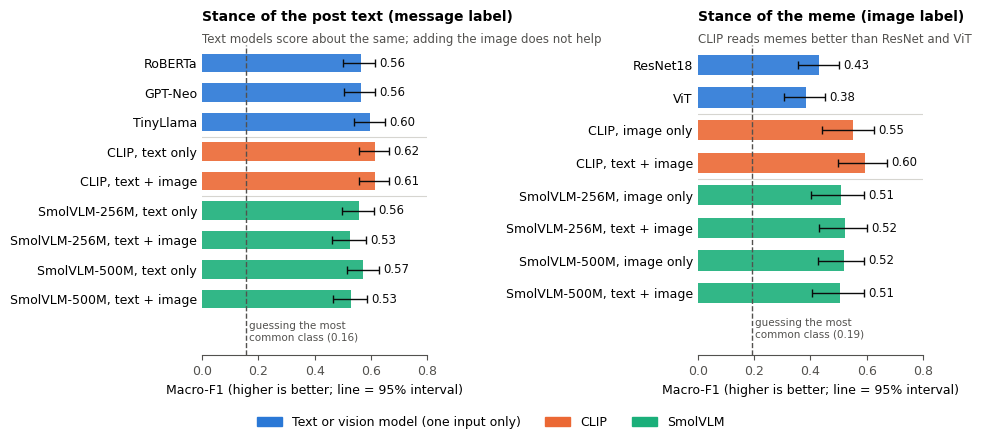

In [32]:
FIG1_NOTES = {"message": "Text models score about the same; adding the image does not help",
              "image":   "CLIP reads memes better than ResNet and ViT"}

plt.rcParams.update({"font.family": "sans-serif", "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.spines.left": False, "axes.edgecolor": "#52514e",
                     "xtick.color": "#52514e", "savefig.facecolor": "white", "figure.facecolor": "white"})
GROUP_COLORS = {"single": "#2a78d6", "CLIP": "#eb6834", "SmolVLM": "#1baf7a"}
INK, MUTED = "#0b0b0b", "#52514e"
SHOW_NAME = {"RoBERTa-base": "RoBERTa", "GPT-Neo-125M": "GPT-Neo", "TinyLlama-1.1B": "TinyLlama",
             "ResNet18": "ResNet18", "ViT-B/16": "ViT", "CLIP Text": "CLIP, text only", "CLIP Image": "CLIP, image only",
             "CLIP Text + Image": "CLIP, text + image",
             **{f"SmolVLM-{s} {i}": f"SmolVLM-{s}, {i}" for s in SIZES for i in ("text only", "image only", "text + image")}}
FIG1 = {"message": ("Stance of the post text (message label)",
                    C1_SYSTEMS[:3] + ["CLIP Text", "CLIP Text + Image"]
                    + [f"SmolVLM-{s} {i}" for s in SIZES for i in ("text only", "text + image")]),
        "image":   ("Stance of the meme (image label)",
                    C2_SYSTEMS[:2] + ["CLIP Image", "CLIP Text + Image"]
                    + [f"SmolVLM-{s} {i}" for s in SIZES for i in ("image only", "text + image")])}
group_of = lambda n: SYSTEMS[n][0] if SYSTEMS[n][0] in ("CLIP", "SmolVLM") else "single"

fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.4))
for ax, (lab, (title, names)) in zip(axes, FIG1.items()):
    T = score_table(lab, names); ys = np.arange(len(T))[::-1]; grp = [group_of(n) for n in names]
    for yv, (_, r), g in zip(ys, T.iterrows(), grp):
        ax.barh(yv, r["Macro-F1"], height=0.62, color=GROUP_COLORS[g], alpha=0.9)
        ax.errorbar(r["Macro-F1"], yv, xerr=[[r["Macro-F1"] - r["CI low"]], [r["CI high"] - r["Macro-F1"]]],
                    color=INK, lw=1, capsize=3)
        ax.text(r["CI high"] + 0.015, yv, f"{r['Macro-F1']:.2f}", va="center", fontsize=8.5, color=INK)
    for i in range(1, len(grp)):                    # thin line between model groups
        if grp[i] != grp[i - 1]:
            ax.axhline(ys[i] + 0.5, color="#d6d5d0", lw=0.8)
    maj = SCORES[(lab, "Majority class")][0]
    ax.axvline(maj, color=MUTED, ls="--", lw=1)
    ax.text(maj + 0.01, ys[-1] - 0.75, f"guessing the most\ncommon class ({maj:.2f})", fontsize=7.5, color=MUTED, va="top")
    ax.set_yticks(ys); ax.set_yticklabels([SHOW_NAME[n] for n in names]); ax.tick_params(axis="y", length=0)
    ax.set_xlim(0, 0.8 if T["CI high"].max() < 0.72 else 1.0); ax.set_ylim(-1.9, len(T) - 0.4)
    ax.set_xlabel("Macro-F1 (higher is better; line = 95% interval)")
    ax.set_title(title + ("\n" if FIG1_NOTES[lab] else ""), loc="left", fontweight="bold", fontsize=10)
    if FIG1_NOTES[lab]:
        ax.text(0, 1.0, FIG1_NOTES[lab], transform=ax.transAxes, fontsize=8.5, color=MUTED, va="bottom")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in GROUP_COLORS.values()]
fig.legend(handles, ["Text or vision model (one input only)", "CLIP", "SmolVLM"], loc="lower center", ncol=3, frameon=False)
plt.tight_layout(rect=(0, 0.06, 1, 1))
for ext in ("png", "pdf"):
    plt.savefig(OUT / f"figure1_overview.{ext}", dpi=300, bbox_inches="tight")
plt.show()

## Additional Analysis (Supplement)
- RoBERTa + ResNet18: two separate models joined by placing their vectors side by side.
- SmolVLM vs CLIP, both with text + image: one model reading text and image together vs two encoders joined.
- Balanced accuracy (average recall over the four classes) for every system. Guessing the most common class scores 0.25.

In [33]:
SUPP = OUT / "supplement"
S1 = pd.concat([score_table(lab, ["Majority class", single, "RoBERTa + ResNet18", "CLIP Text + Image"]).assign(Label=lab)
                for lab, single in (("message", "RoBERTa-base"), ("image", "ResNet18"))])
show(S1[["Label", "System", "Macro-F1", "CI low", "CI high"]], "Table S1a. RoBERTa + ResNet18", "supplement/table_S1a_fusion.csv")
show(diff_table([("message", "RoBERTa + ResNet18", "RoBERTa-base"), ("image", "RoBERTa + ResNet18", "ResNet18"),
                 ("message", "CLIP Text + Image", "RoBERTa + ResNet18"), ("image", "CLIP Text + Image", "RoBERTa + ResNet18")]),
     "Table S1b. RoBERTa + ResNet18 compared with its single models and with CLIP", "supplement/table_S1b_fusion_differences.csv")

show(diff_table([(lab, f"SmolVLM-{s} text + image", "CLIP Text + Image") for lab in ("message", "image") for s in SIZES]),
     "Table S2. SmolVLM vs CLIP, text + image", "supplement/table_S2_smolvlm_vs_clip.csv")

rows = []
for lab in ("message", "image"):
    names = [n for n in SYSTEMS if (lab, n) in PRED and SYSTEMS[n][0] in ("CLIP", "SmolVLM")]
    for n in names:
        f1 = np.mean([f1_score(Y[lab], p, labels=CLASSES, average=None, zero_division=0) for p in PRED[(lab, n)]], axis=0)
        rows.append({"Label": lab, "System": n, **dict(zip(CLASSES, f1))})
S3 = pd.DataFrame(rows)
S3.round(4).to_csv(SUPP / "table_S3_per_class_f1.csv", index=False)
counts = {lab: df[col].value_counts().reindex(CLASSES).fillna(0).astype(int).to_dict() for lab, col in LABEL_COLS.items()}
print("\n=== Table S3. Per-class F1 (mean over repeats) ===\nposts per class:", counts)
print(S3.round(2).to_string(index=False))

rows = []
for lab in ("message", "image"):
    for n in [n for n in SYSTEMS if (lab, n) in PRED]:
        full, boots = boot_scores(lab, n, balanced_accuracy); lo, hi = ci(boots)
        rows.append({"Label": lab, "System": n, "Balanced accuracy": full, "CI low": lo, "CI high": hi})
S4 = pd.DataFrame(rows)
S4.round(4).to_csv(SUPP / "table_S4_balanced_accuracy.csv", index=False)
S4["Balanced accuracy [95% interval]"] = [f"{e:.2f} {fmt_ci(l, h)}" for e, l, h in zip(S4.pop("Balanced accuracy"), S4.pop("CI low"), S4.pop("CI high"))]
print("\n=== Table S4. Balanced accuracy, every system ===")
print(S4.to_string(index=False))

print("\nAll tables and figures saved in", OUT)


=== Table S1a. RoBERTa + ResNet18 ===
  Label             System Macro-F1 [95% interval]
message     Majority class       0.16 [0.14, 0.17]
message       RoBERTa-base       0.56 [0.50, 0.61]
message RoBERTa + ResNet18       0.51 [0.46, 0.57]
message  CLIP Text + Image       0.61 [0.56, 0.66]
  image     Majority class       0.19 [0.18, 0.21]
  image           ResNet18       0.43 [0.36, 0.50]
  image RoBERTa + ResNet18       0.44 [0.38, 0.50]
  image  CLIP Text + Image       0.60 [0.50, 0.67]

=== Table S1b. RoBERTa + ResNet18 compared with its single models and with CLIP ===
  Label           System A           System B  Macro-F1 A  Macro-F1 B Difference (A - B) [95% interval]
message RoBERTa + ResNet18       RoBERTa-base        0.51        0.56              -0.05 [-0.10, -0.01]
  image RoBERTa + ResNet18           ResNet18        0.44        0.43                0.01 [-0.07, 0.10]
message  CLIP Text + Image RoBERTa + ResNet18        0.61        0.51                 0.10 [0.04, 0.17]
 